# 01_Docked_TAS2R14_intracellular_binders

In [1]:
import pandas as pd
import numpy as np
import os

import sys
sys.path.append('../src/TAS2Rs_cofolding_utils/')
from complex_utils import get_ligands_interactions, get_ligands_rmsd
from receptor_region import ReceptorRegionClassyfier

import seaborn as sns
palette = sns.color_palette('Paired')

In [2]:
# setup ReceptorRegionClassyfier
path_to_msa = '../data/sequences/TAS2Rs T-Coffee aligned.fa'
path_to_regions = '../data/sequences/TAS2Rs_known_regions.xlsx'
region_classyfier = ReceptorRegionClassyfier(path_to_regions, path_to_msa)

### Load TAS2R cryo-EM complexes

In [3]:
# Load metadata on TAS2R cryo-EM complexes
path_to_meta_file = '../data/TAS2R_cryoEM_compexes/TAS2R_cryoEM_complexes_meta.xlsx'
TAS2R_cryoEM_complexes_meta = pd.read_excel(path_to_meta_file)
# Obtain the PDB codes for the published TAS2R cryo-EM complexes
published_TAS2R_cryoEM_pdb_codes = set(TAS2R_cryoEM_complexes_meta['PDB code'].dropna())

In [4]:
# Load TAS2R cryo-EM complexes with one ligand per complex
TAS2R_cryoEM_complexes = []
path_to_TAS2R_cryoEM_complexes_dir = '../data/TAS2R_cryoEM_compexes/one_ligand_per_complex/'

pdb_files = [file for file in os.listdir(path_to_TAS2R_cryoEM_complexes_dir) if file.endswith('.pdb')]

for pdb_file in pdb_files:

    ligand, receptor, Galpha, pdb_code = pdb_file.rstrip('.pdb').split('-')
    ligand = ligand.replace('_', ' ')
    if '(' in ligand:
        ligand = ligand[:-3]

    if not pdb_code in published_TAS2R_cryoEM_pdb_codes:
        continue

    path_to_file = os.path.join(path_to_TAS2R_cryoEM_complexes_dir, pdb_file)
    interactions = get_ligands_interactions(path_to_file)
    interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
    binding_site = interactions['Region'].value_counts().idxmax()
    TAS2R_cryoEM_complexes.append([path_to_file, pdb_file, ligand, receptor, Galpha, pdb_code, interactions, binding_site])

TAS2R_cryoEM_complexes_df = pd.DataFrame(TAS2R_cryoEM_complexes, columns=['path to file', 'file name', 'ligand', 'receptor', 'Gα', 'PDB code', 'interactions', 'binding site'])
print(f'Number of cryo-EM complexes: {len(TAS2R_cryoEM_complexes_df['PDB code'].unique())}')

Number of cryo-EM complexes: 27


In [5]:
files_to_drop = ['aristolochic_acid(2)-TAS2R14-miniGgust-8XQL.pdb', 'aristolochic_acid-TAS2R14-Ggust-8XQP.pdb', 'cholesterol(2)-TAS2R14-Gi1-8XQT.pdb']
TAS2R_cryoEM_complexes_df = TAS2R_cryoEM_complexes_df[~TAS2R_cryoEM_complexes_df['file name'].isin(files_to_drop)].reset_index(drop=True)

### Load receptor folding + docking data

In [6]:
docking_data = []

path_to_folder = '../predictions/Docked_TAS2R14_intracellular_binders/'
pdb_files = [file for file in os.listdir(path_to_folder) if file.endswith('.pdb')]

for pdb_file in pdb_files:
    
    if 'Boltz-2' in pdb_file:
        receptor, _, _, ligand, pose = [el.replace('_', ' ') for el in pdb_file.rstrip('.pdb').split('-')]
        tool = 'Boltz-2'
    else:
        receptor, tool, ligand, pose = [el.replace('_', ' ') for el in pdb_file.rstrip('.pdb').split('-')]
    receptor = receptor.lstrip('h')

    path_to_file = os.path.join(path_to_folder, pdb_file)

    # получаем данные по взаимодействиям
    interactions = get_ligands_interactions(path_to_file)
    # классифицируем регион остатка
    interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
    # устанавливаем сайт связывания
    binding_site = interactions['Region'].value_counts().idxmax()

    docking_data.append([path_to_file, pdb_file, receptor, tool, ligand, pose, interactions, binding_site])

docking_data_df = pd.DataFrame(docking_data, columns=['path to file', 'file name', 'receptor', 'tool',  'ligand', 'pose', 'interactions', 'binding site'])

In [7]:
docking_ligands_rmsd_distribution = []
for (receptor, tool, ligand, binding_site), docking_data_sub_df in docking_data_df.groupby(['receptor', 'tool', 'ligand', 'binding site']):
    TAS2R_cryoEM_complexes_sub_df = TAS2R_cryoEM_complexes_df[(TAS2R_cryoEM_complexes_df['receptor'] == receptor) &
                                                           (TAS2R_cryoEM_complexes_df['ligand'] == ligand) &
                                                           (TAS2R_cryoEM_complexes_df['binding site'] == binding_site)].reset_index()
    if TAS2R_cryoEM_complexes_sub_df.empty:
        ligands_rmsd = np.nan
        docking_ligands_rmsd_distribution.append([receptor, tool, site, ligand, binding_site, ligands_rmsd])
    else:
        for path_to_cryoEM_complex in TAS2R_cryoEM_complexes_sub_df['path to file']:
            for path_to_docked_complex in docking_data_sub_df['path to file']:
                ligands_rmsd = get_ligands_rmsd(path_to_cryoEM_complex, path_to_docked_complex)
                docking_ligands_rmsd_distribution.append([receptor, tool, ligand, binding_site, ligands_rmsd])
docking_ligands_rmsd_distribution = pd.DataFrame(docking_ligands_rmsd_distribution, columns=['receptor', 'tool', 'ligand', 'binding site', 'ligands rmsd'])
docking_ligands_rmsd_distribution.dropna(inplace=True, ignore_index=True)

/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:1336: UserWarning: Found missing chainIDs. Corresponding atoms will use value of 'X'
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-packages/MDAnalysis/coordinates/PDB.py:1336: UserWarning: Found missing chainIDs. Corresponding atoms will use value of 'X'
  warnings.warn(
/sci/labs/mashaniv/evgenii.ziaikin/anaconda3/envs/TAS2Rs_folding/lib/python3.12/site-package

In [8]:
ligands = ['compound 28.1', 'flufenamic acid', 'aristolochic acid']
docking_ligands_rmsd_distribution['ligand'] = pd.Categorical(docking_ligands_rmsd_distribution['ligand'], categories=ligands, ordered=True)
docking_ligands_rmsd_distribution['strategy'] = docking_ligands_rmsd_distribution['tool'].apply(lambda tool: f'{tool} + Glide')

In [10]:
grouped = docking_ligands_rmsd_distribution.groupby(['ligand', 'strategy'])['ligands rmsd']
mean = grouped.mean().to_frame('mean')
std = grouped.std().to_frame('std')

summary = mean.join(std).round(1).reset_index()
summary['rmsd'] = summary['mean'].astype('str') + ' ± ' + summary['std'].astype('str')
summary

/tmp/ipykernel_3773256/1934480478.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = docking_ligands_rmsd_distribution.groupby(['ligand', 'strategy'])['ligands rmsd']


,ligand,strategy,mean,std,rmsd
0,compound 28.1,AF3 + Glide,11.7,1.2,11.7 ± 1.2
1,compound 28.1,Boltz-2 + Glide,10.0,2.4,10.0 ± 2.4
2,flufenamic acid,AF3 + Glide,12.2,0.3,12.2 ± 0.3
3,flufenamic acid,Boltz-2 + Glide,7.0,1.0,7.0 ± 1.0
4,aristolochic acid,AF3 + Glide,13.1,0.6,13.1 ± 0.6
5,aristolochic acid,Boltz-2 + Glide,13.5,1.3,13.5 ± 1.3


/tmp/ipykernel_3773256/2952480215.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  chart.set_xticklabels(new_labels)


<Axes: title={'center': 'TAS2R14 intracellular pocket'}, ylabel='RMSD, Å'>

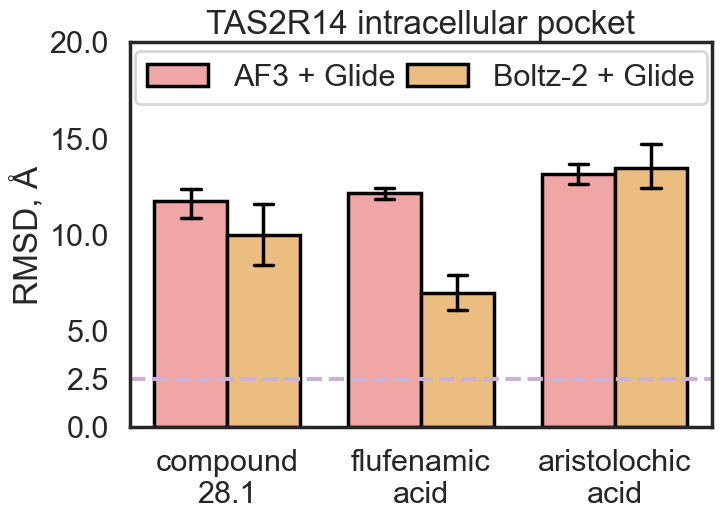

In [11]:
sns.set(rc={'figure.figsize':(7.5, 5)}, style='white', context='poster')

chart = sns.barplot(docking_ligands_rmsd_distribution, x='ligand', y='ligands rmsd', hue='strategy', errorbar=('ci', 100), err_kws={'color': 'black', 'linewidth': 2.5}, capsize=0.2, linewidth=2.5, edgecolor='black',
                    width=0.75, palette=[palette[4], palette[6]])
# format the names of complexes
labels = [item.get_text() for item in chart.get_xticklabels()]
new_labels = [label.split(' - ')[0] for label in labels]
new_labels = [label.replace(' ', '\n') if ' ' in label else label for label in new_labels]
chart.set_xticklabels(new_labels)
chart.set(ylabel='RMSD, Å', xlabel='', ylim=(0, 20), yticks=np.append(np.arange(0, 21, 5), 2.5), title='TAS2R14 intracellular pocket')
chart.axhline(2.5, color=palette[8], linestyle='--')
sns.move_legend(chart, 'lower center', bbox_to_anchor=(0.5, 0.8), ncol=2, title='', columnspacing=0.4)
chart.figure.savefig('../figures/supplementary/Supplementary Figure 1A.png', dpi=300, bbox_inches='tight')
chart